In [1]:
# Make the project importable whether this runs from notebooks/ or the repo root.
import pathlib
import sys

_root = next(
    p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    if (p / "src" / "__init__.py").exists()
)
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

# 04 · Train/Serve Skew

**The second silent killer.** Point-in-time correctness makes the *training* set honest.
Train/serve skew is the other half: the feature a model sees in production must be computed the
**same way** as the feature it trained on. When two people implement the same feature twice — a
slightly different window, null rule, or rounding — the two drift. Both paths run without error;
only the production metric suffers.

Here the training feature is `txn_count_30d` (a 30-day window) and a serving reimplementation
uses a **14-day** window. We measure the disagreement and — the sharp lesson — show that **AUC
barely notices while accuracy at the deployed threshold collapses.**

In [2]:
from src.artifacts import apply_style, save_figure, save_json, BLUE, ORANGE, MUTED
from src.config import settings, ENTITY_COL, EVENT_TS_COL, LABEL_COL
from src.datasets.events import load
from src.features.definitions import txn_count_window
from src.evaluation.skew import run_skew_experiment
import matplotlib.pyplot as plt
import numpy as np

apply_style()
ds = load(settings)
result = run_skew_experiment(ds, settings)
print(f"correct window  : {settings.window_days} days")
print(f"serving window  : {settings.skew_window_days} days  (the reimplementation)")
print(f"disagreement    : {result.disagreement_rate:.1%} of rows")
print(f"mean abs diff   : {result.mean_abs_diff:.2f} transactions")

correct window  : 30 days
serving window  : 14 days  (the reimplementation)
disagreement    : 96.2% of rows
mean abs diff   : 6.71 transactions


## They disagree on almost every row

Compute the feature both ways from the **same** raw activity and plot them against each other.
Points off the dashed `y = x` line are rows where training and serving would disagree — a model
trained on the blue axis is served the value on the orange axis.

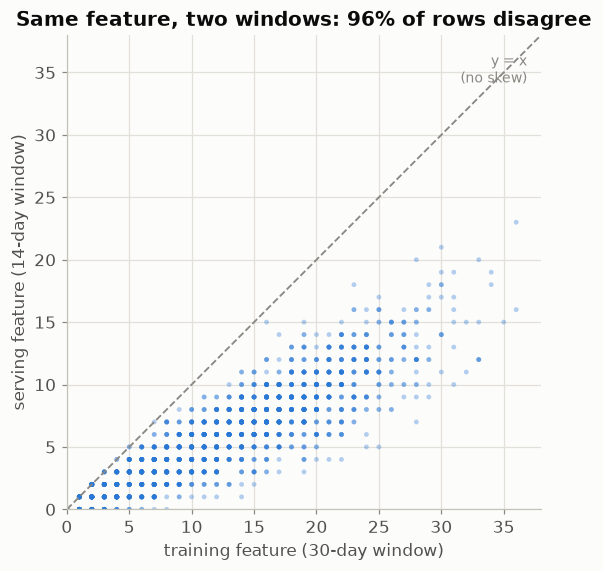

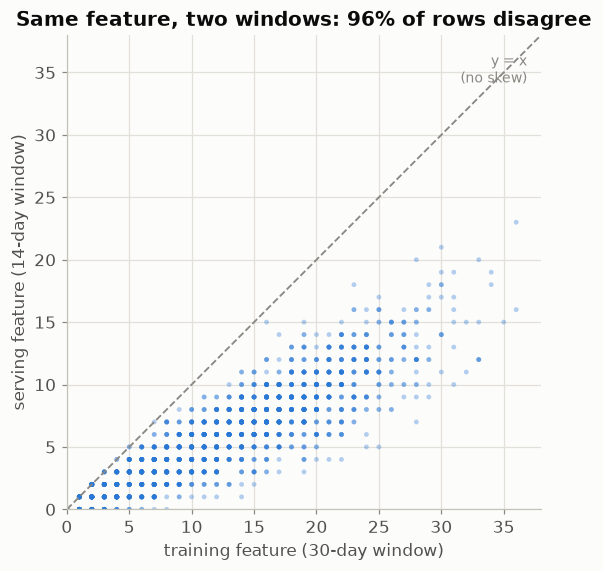

In [3]:
requests = ds.events[[ENTITY_COL, EVENT_TS_COL]]
correct = txn_count_window(ds.activity, requests, settings.window_days)
divergent = txn_count_window(ds.activity, requests, settings.skew_window_days)

lim = max(correct.max(), divergent.max()) + 2
fig, ax = plt.subplots(figsize=(5.6, 5.6))
ax.scatter(correct, divergent, s=10, color=BLUE, alpha=0.35, edgecolor="none")
ax.plot([0, lim], [0, lim], color=MUTED, ls="--", lw=1.2)
ax.text(lim * 0.97, lim * 0.9, "y = x\n(no skew)", color=MUTED, ha="right", fontsize=9)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_aspect("equal")
ax.set_xlabel(f"training feature ({settings.window_days}-day window)")
ax.set_ylabel(f"serving feature ({settings.skew_window_days}-day window)")
ax.set_title(f"Same feature, two windows: {result.disagreement_rate:.0%} of rows disagree")
save_figure(fig, "04_skew_scatter")
fig

## The skew is silent: AUC hides it, accuracy exposes it

A model is trained on the correct feature and then served the divergent one. **ROC AUC** (a
pure ranking metric) hardly moves — so a quick offline sanity check misses the bug entirely.
But **accuracy at the deployed 0.5 threshold** drops sharply, because the served feature sits
on a different scale than the one the decision boundary was fit to.

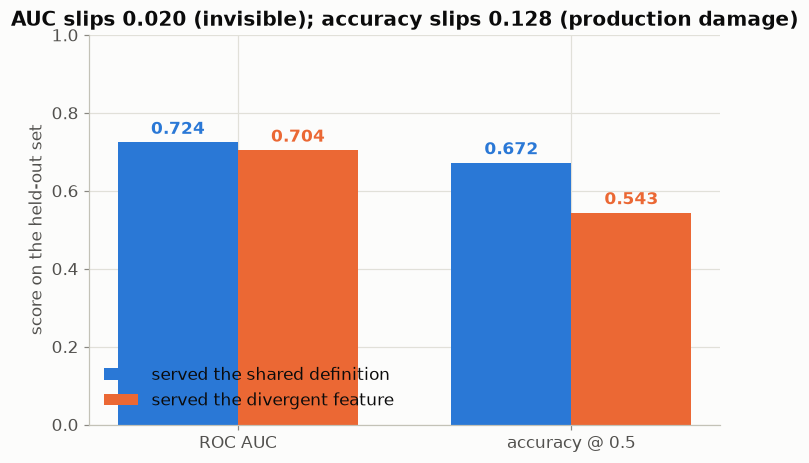

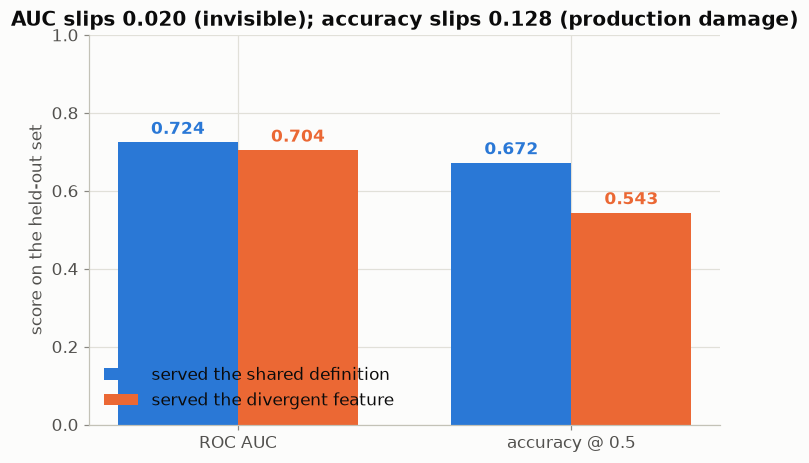

In [4]:
metrics = ["ROC AUC", "accuracy @ 0.5"]
correct_vals = [result.correct_auc, result.correct_accuracy]
skew_vals = [result.skew_auc, result.skew_accuracy]
x = np.arange(len(metrics))
width = 0.36
fig, ax = plt.subplots(figsize=(7.4, 4.6))
b1 = ax.bar(x - width / 2, correct_vals, width, color=BLUE, label="served the shared definition")
b2 = ax.bar(x + width / 2, skew_vals, width, color=ORANGE, label="served the divergent feature")
ax.bar_label(b1, fmt="%.3f", padding=3, fontweight="bold", color=BLUE)
ax.bar_label(b2, fmt="%.3f", padding=3, fontweight="bold", color=ORANGE)
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.0)
ax.set_ylabel("score on the held-out set")
ax.set_title(
    f"AUC slips {result.auc_slip:.3f} (invisible); "
    f"accuracy slips {result.accuracy_slip:.3f} (production damage)"
)
ax.legend(frameon=False, loc="lower left")
save_figure(fig, "04_skew_metrics")
fig

## The fix is structural: one shared definition

Route both training and serving through the **one** definition
(`src.features.definitions.txn_count_window`) with the same window, materialized to the online
store, and the gap vanishes — the served value *is* the trained value by construction. This is
the structural reason feature stores exist, not a nicety.

**Connection to drift (`model_drift_detector`):** a *stale* online value is its own kind of
skew — the definition is right but the materialized value is out of date. Freshness is the
serving-side of the same concern.

In [5]:
payload = {
    "windows": {"training": settings.window_days, "serving": settings.skew_window_days},
    "disagreement_rate": result.disagreement_rate,
    "mean_abs_diff": result.mean_abs_diff,
    "auc": {"correct": result.correct_auc, "divergent": result.skew_auc, "slip": result.auc_slip},
    "accuracy": {
        "correct": result.correct_accuracy,
        "divergent": result.skew_accuracy,
        "slip": result.accuracy_slip,
    },
    "takeaway": (
        "AUC barely moved, so the skew was invisible to a ranking check, but accuracy at the "
        "deployed threshold collapsed. One shared definition, materialized to the online store, "
        "removes the gap."
    ),
}
print(save_json(payload, "04_skew_results"))
payload["accuracy"]

/workspaces/feature_store_101/outputs/json/04_skew_results.json


{'correct': 0.6716666666666666,
 'divergent': 0.5433333333333333,
 'slip': 0.1283333333333333}

## Next

**[05 · Feast Locally](05_feast_locally.ipynb)** — the real tool, entirely local and keyless,
producing the same point-in-time results as our hundred-line store.